P1: Raw accelerometer channels versus time

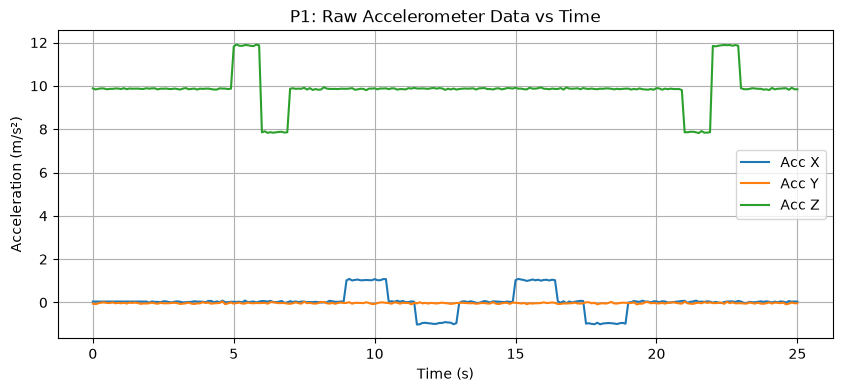

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

# 1. Load Data
df = pd.read_excel("Drone_Sensor_Data.xlsx", sheet_name=0)
time = df['time_s'].values
dt = 0.1

# 2. Phase 1: Bias Estimation
calib_window = df[df['time_s'] < 5.0]
bias_acc_x = calib_window['acc_x_mps2'].mean()
bias_acc_y = calib_window['acc_y_mps2'].mean()
bias_acc_z = calib_window['acc_z_mps2'].mean() - 9.81
bias_gyro_x = calib_window['gyro_x_rads'].mean()
bias_gyro_y = calib_window['gyro_y_rads'].mean()
bias_gyro_z = calib_window['gyro_z_rads'].mean()

acc_x_corr = df['acc_x_mps2'].values - bias_acc_x
acc_y_corr = df['acc_y_mps2'].values - bias_acc_y
acc_z_corr = df['acc_z_mps2'].values - bias_acc_z
gyro_z_corr = df['gyro_z_rads'].values - bias_gyro_z

# 3. Phase 2: Orientation & Kinematics
yaw = cumulative_trapezoid(gyro_z_corr, time, initial=0) 

a_X = np.zeros_like(time)
a_Y = np.zeros_like(time)
a_Z = np.zeros_like(time)

for i in range(len(time)):
    psi = yaw[i]
    R_z = np.array([
        [np.cos(psi), -np.sin(psi), 0],
        [np.sin(psi),  np.cos(psi), 0],
        [0,            0,           1]
    ])
    a_body = np.array([acc_x_corr[i], acc_y_corr[i], acc_z_corr[i]])
    a_world = R_z.dot(a_body)
    
    a_X[i] = a_world[0]
    a_Y[i] = a_world[1]
    a_Z[i] = a_world[2] - 9.81 

v_X = cumulative_trapezoid(a_X, time, initial=0)
v_Y = cumulative_trapezoid(a_Y, time, initial=0)
v_Z = cumulative_trapezoid(a_Z, time, initial=0)

pos_X = cumulative_trapezoid(v_X, time, initial=0)
pos_Y = cumulative_trapezoid(v_Y, time, initial=0)
pos_Z = cumulative_trapezoid(v_Z, time, initial=0)
plt.figure(figsize=(10, 4))
plt.plot(time, df['acc_x_mps2'], label='Acc X')
plt.plot(time, df['acc_y_mps2'], label='Acc Y')
plt.plot(time, df['acc_z_mps2'], label='Acc Z')
plt.title('P1: Raw Accelerometer Data vs Time')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s²)')
plt.legend()
plt.grid(True)
plt.show()

### P2: Raw gyroscope channels versus time

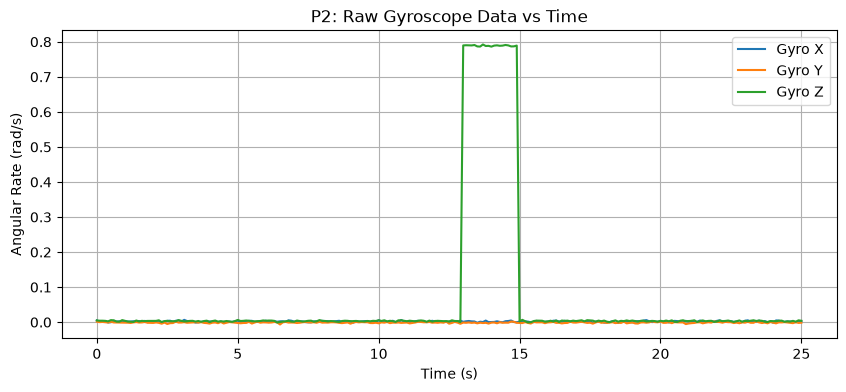

In [2]:
plt.figure(figsize=(10, 4))
plt.plot(time, df['gyro_x_rads'], label='Gyro X')
plt.plot(time, df['gyro_y_rads'], label='Gyro Y')
plt.plot(time, df['gyro_z_rads'], label='Gyro Z')
plt.title('P2: Raw Gyroscope Data vs Time')
plt.xlabel('Time (s)')
plt.ylabel('Angular Rate (rad/s)')
plt.legend()
plt.grid(True)
plt.show()

### P3: Estimated yaw $\Psi(t)$

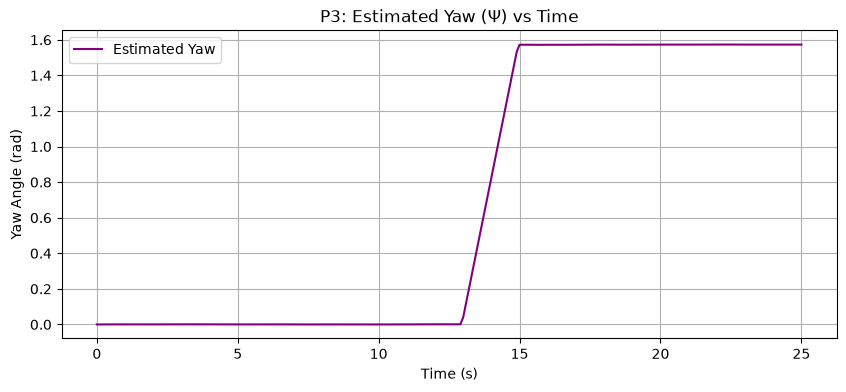

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(time, yaw, color='purple', label='Estimated Yaw')
plt.title('P3: Estimated Yaw (Ψ) vs Time')
plt.xlabel('Time (s)')
plt.ylabel('Yaw Angle (rad)')
plt.legend()
plt.grid(True)
plt.show()

### P4: World-frame translational acceleration

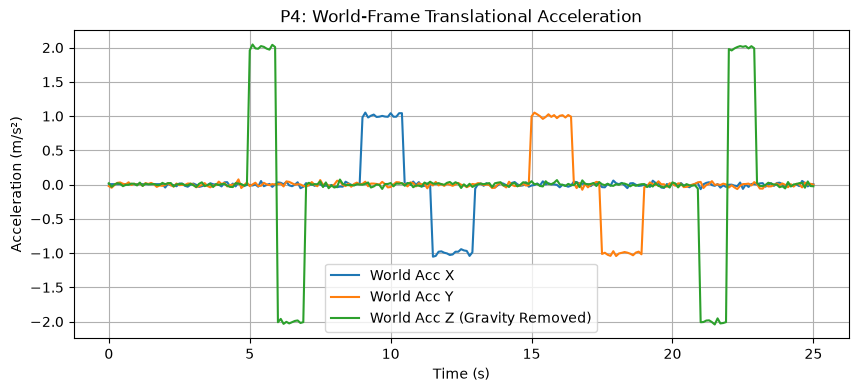

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(time, a_X, label='World Acc X')
plt.plot(time, a_Y, label='World Acc Y')
plt.plot(time, a_Z, label='World Acc Z (Gravity Removed)')
plt.title('P4: World-Frame Translational Acceleration')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s²)')
plt.legend()
plt.grid(True)
plt.show()

### P5: Estimated velocity

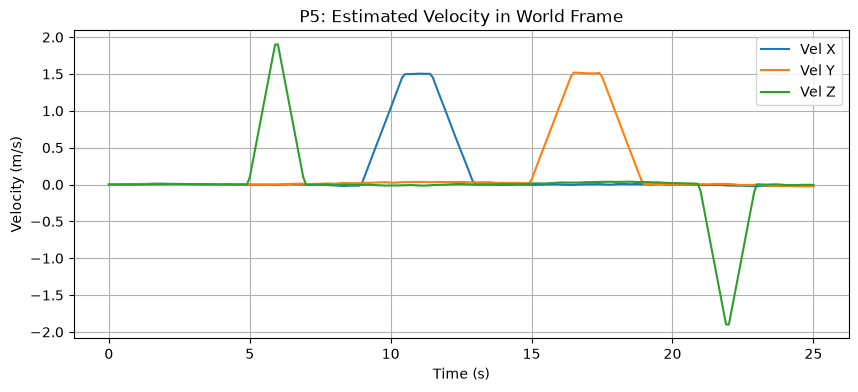

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(time, v_X, label='Vel X')
plt.plot(time, v_Y, label='Vel Y')
plt.plot(time, v_Z, label='Vel Z')
plt.title('P5: Estimated Velocity in World Frame')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()

### P6: Estimated position

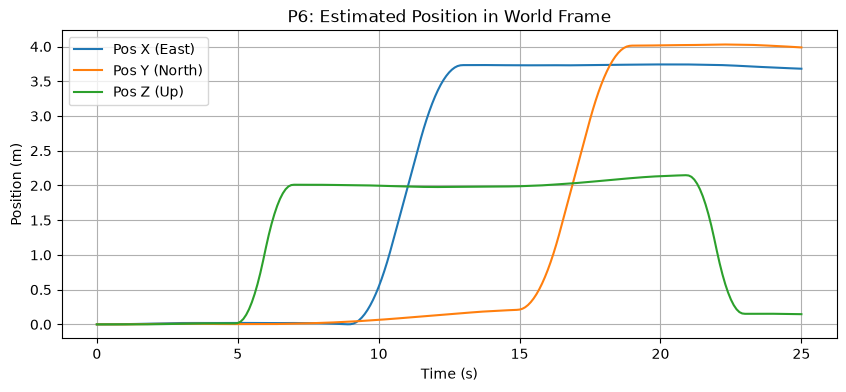

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(time, pos_X, label='Pos X (East)')
plt.plot(time, pos_Y, label='Pos Y (North)')
plt.plot(time, pos_Z, label='Pos Z (Up)')
plt.title('P6: Estimated Position in World Frame')
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

### P7: 3-D reconstructed trajectory

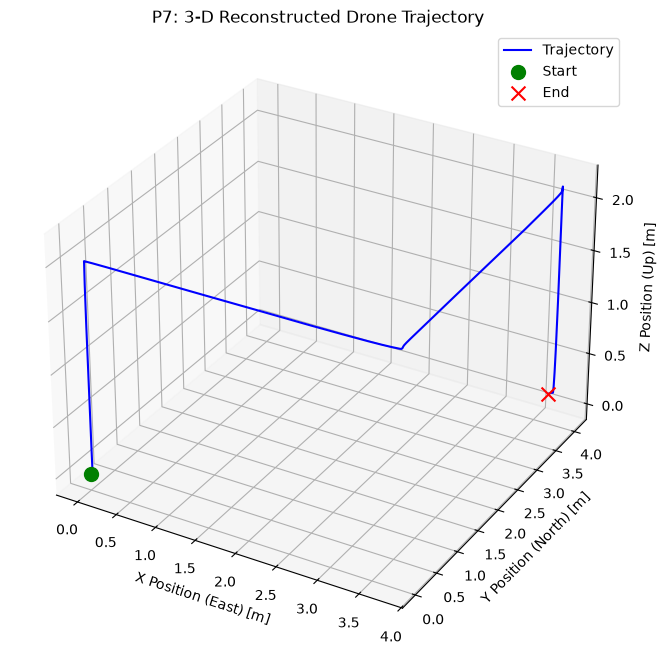

In [11]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(pos_X, pos_Y, pos_Z, label='Trajectory', color='blue')
ax.scatter(pos_X[0], pos_Y[0], pos_Z[0], color='green', s=100, label='Start', marker='o')
ax.scatter(pos_X[-1], pos_Y[-1], pos_Z[-1], color='red', s=100, label='End', marker='x')
ax.set_title('P7: 3-D Reconstructed Drone Trajectory')
ax.set_xlabel('X Position (East) [m]')
ax.set_ylabel('Y Position (North) [m]')
ax.set_zlabel('Z Position (Up) [m]')
ax.legend()
plt.show()

### P8: IMU altitude versus barometer altitude

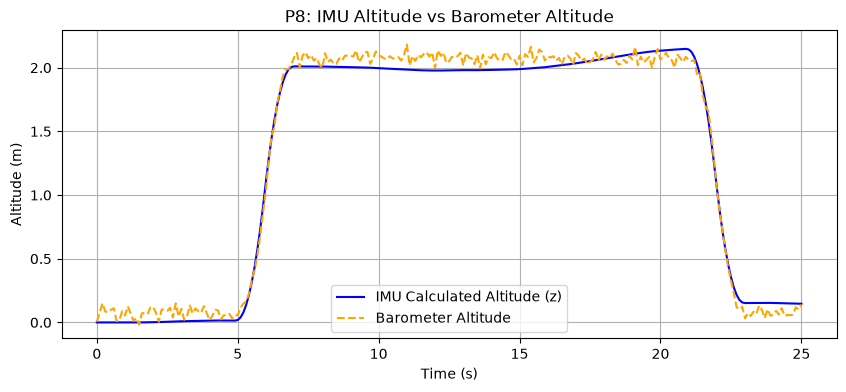

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(time, pos_Z, label='IMU Calculated Altitude (z)', color='blue')
plt.plot(time, df['baro_alt_m'], label='Barometer Altitude', color='orange', linestyle='--')
plt.title('P8: IMU Altitude vs Barometer Altitude')
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.legend()
plt.grid(True)
plt.show()